# 🛡️ PhishGuard: Phishing Website Detection System Using Machine Learning

---

### **Academic Submission Details**
* **Project Title:** PhishGuard — Phishing Website Detection System Using Machine Learning
* **Student Name:** Saransh
* **Course:** B.Tech Computer Science and Engineering (CSE), 3rd Year
* **Project Level:** Beginner-Friendly Academic Mini-Project
* **Language & Environment:** Python 3 | Jupyter Notebook
* **Dataset Attribution:** Mohammad, R., Thabtah, F., & McCluskey, L. (2012). *Phishing Websites Dataset*, UCI Machine Learning Repository (ID: 327, DOI: [10.24432/C51W2X](https://doi.org/10.24432/C51W2X)).

---

## 📌 1. Project Overview & Cybersecurity Context

### What is Phishing?
Phishing is one of the oldest yet most damaging cyber threats worldwide. It is a form of social engineering where attackers deploy deceptive websites mimicking legitimate organizations (such as banks, payment gateways, social networks, or enterprise portals) to harvest sensitive personal data: login credentials, credit card numbers, and session cookies.

### Why Traditional Defenses Fail
1. **Static Blacklists:** Traditional security gateways rely on domain and URL blacklists (e.g., Google Safe Browsing, PhishTank). While accurate, blacklists are purely reactive. Attackers routinely generate thousands of short-lived domains using fast-flux DNS, dynamic hosting, and Automated Domain Generation Algorithms (DGAs). A zero-day phishing site is typically alive for only 4 to 8 hours—long before it gets manually reported and added to blacklists.
2. **Evasion Techniques:** Attackers leverage obfuscated characters (homograph / punycode attacks), IP hostnames, multi-tier subdomains, and legitimate cloud hosting services to bypass standard security filters.

### The Role of Machine Learning
Machine Learning (ML) enables **proactive, automated classification**. By learning statistical patterns, structural heuristics, and behavioral telemetry from past legitimate and malicious websites, trained classifiers can evaluate unfamiliar websites instantaneously with high accuracy and high recall.

---


## 📦 2. Environment Setup & Library Imports

In this section, we import standard scientific computing, machine learning, and visualization libraries. We also set reproducible seeds so that all experiment runs yield identical, verifiable results.


In [1]:
# Standard library imports
import os
import sys
import re
import ipaddress
import urllib.parse
import warnings

# Suppress minor warnings for clean notebook presentation
warnings.filterwarnings('ignore')

# Scientific computing & data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning: data splitting & models
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Machine learning: evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Set global random state for reproducible science
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure Matplotlib visual defaults
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.autolayout'] = True
plt.rcParams['font.size'] = 10

print(f"✅ Python environment ready! Python version: {sys.version.split()[0]}")
print(f"✅ NumPy: {np.__version__} | Pandas: {pd.__version__}")


✅ Python environment ready! Python version: 3.12.0
✅ NumPy: 2.5.4 | Pandas: 3.1.0


## 📂 3. Dataset Loading & Inspection (UCI #327)

### Official Dataset Description
* **Source:** UCI Machine Learning Repository
* **Dataset Name:** Phishing Websites Dataset (ID: 327)
* **Citation:** Mohammad, R., Thabtah, F., and McCluskey, L. (2012). *An Assessment of Features Related to Phishing Websites Using an Automated Technique.*
* **Scope:** 11,055 instances characterized across 30 website telemetry features spanning URL structure, SSL/TLS certificates, domain registration, anchor links, and web traffic.

> **Important Technical Note:** The UCI dataset contains **30 extracted website telemetry features**, not raw URL strings. Feature extraction on live websites involves DNS lookups, certificate validation, and HTML DOM parsing.

### Resilient Data Loader
To ensure 100% academic reproducibility, the code below attempts to fetch the dataset directly from the official UCI repository via `ucimlrepo`. If network access is restricted or offline, it gracefully falls back to a locally cached copy (`data/phishing_websites_uci_327.csv`).


In [2]:
def load_phishing_dataset():
    """
    Loads UCI Phishing Websites dataset (ID 327) via ucimlrepo with local cache fallback.
    """
    cache_path = os.path.join('data', 'phishing_websites_uci_327.csv')
    
    # Check if local cache already exists
    if os.path.exists(cache_path):
        print(f"📁 Loading local cached dataset from: {cache_path}")
        df = pd.read_csv(cache_path)
        return df
    
    print("🌐 Connecting to UCI Machine Learning Repository (Dataset ID: 327)...")
    try:
        from ucimlrepo import fetch_ucirepo
        dataset = fetch_ucirepo(id=327)
        # Combine features and target into a single DataFrame
        df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
        
        # Save local copy for offline reproducibility
        os.makedirs('data', exist_ok=True)
        df.to_csv(cache_path, index=False)
        print(f"✅ Successfully fetched from UCI and cached to {cache_path}")
        return df
    except Exception as e:
        print(f"⚠️ Failed to fetch dataset directly from UCI: {e}")
        print("💡 Troubleshooting Tips:")
        print("   1. Verify your internet connection.")
        print("   2. Install ucimlrepo: `python -m pip install ucimlrepo`")
        print(f"   3. Or manually place the CSV file at '{cache_path}'.")
        raise e

# Execute dataset loading
df = load_phishing_dataset()

# Display core dimensions
print(f"\n📊 Dataset Dimensions: {df.shape[0]:,} Rows (Instances) x {df.shape[1]} Columns (30 Features + 1 Target)")


📁 Loading local cached dataset from: data\phishing_websites_uci_327.csv

📊 Dataset Dimensions: 11,055 Rows (Instances) x 31 Columns (30 Features + 1 Target)


### Preview First 5 Records of the Dataset

In [3]:
# Display first 5 rows
df.head()


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


### Feature Columns and Data Types Audit

In [4]:
# Check column names, non-null counts, and data types
print("Dataset Info Summary:")
df.info()


Dataset Info Summary:
<class 'pandas.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   having_ip_address           11055 non-null  int64
 1   url_length                  11055 non-null  int64
 2   shortining_service          11055 non-null  int64
 3   having_at_symbol            11055 non-null  int64
 4   double_slash_redirecting    11055 non-null  int64
 5   prefix_suffix               11055 non-null  int64
 6   having_sub_domain           11055 non-null  int64
 7   sslfinal_state              11055 non-null  int64
 8   domain_registration_length  11055 non-null  int64
 9   favicon                     11055 non-null  int64
 10  port                        11055 non-null  int64
 11  https_token                 11055 non-null  int64
 12  request_url                 11055 non-null  int64
 13  url_of_anchor               11055 non-null  int64


## 🔍 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis allows us to inspect data quality, verify missing values, analyze duplicate rows, and inspect the target class balance before training models.

### Target Mapping Documentation
In the official UCI Phishing Websites dataset:
* **`1`** = **Legitimate Website** (Benign / Safe)
* **`-1`** = **Phishing Website** (Malicious / Fraudulent)

For binary classification in cybersecurity, we map:
* **`1` (Phishing)**: Positive class (The primary security threat we want to detect)
* **`0` (Legitimate)**: Negative class (Normal benign browsing)

This standard mapping ensures that **Recall** represents the fraction of actual phishing attacks our system successfully intercepts, and **Precision** represents the reliability of security alerts.


In [5]:
# Identify target column (handle case differences if any)
target_col = 'result' if 'result' in df.columns else 'Result'
feature_cols = [col for col in df.columns if col != target_col]

# Check missing values
missing_total = df.isnull().sum().sum()
duplicate_total = df.duplicated().sum()

print("--- Data Quality Audit ---")
print(f"Total Missing Values across all cells: {missing_total}")
print(f"Duplicate Feature Profiles: {duplicate_total:,} rows")
print(f"Number of Feature Attributes: {len(feature_cols)}")

# Target distribution in original encoding
target_counts = df[target_col].value_counts()
print(f"\nOriginal Target Class Distribution ({target_col}):")
print(f"  Class  1 (Legitimate): {target_counts.get(1, 0):,} ({target_counts.get(1, 0)/len(df)*100:.2f}%)")
print(f"  Class -1 (Phishing)  : {target_counts.get(-1, 0):,} ({target_counts.get(-1, 0)/len(df)*100:.2f}%)")


--- Data Quality Audit ---
Total Missing Values across all cells: 0
Duplicate Feature Profiles: 5,206 rows
Number of Feature Attributes: 30

Original Target Class Distribution (result):
  Class  1 (Legitimate): 6,157 (55.69%)
  Class -1 (Phishing)  : 4,898 (44.31%)


### Target Class Distribution Visualization

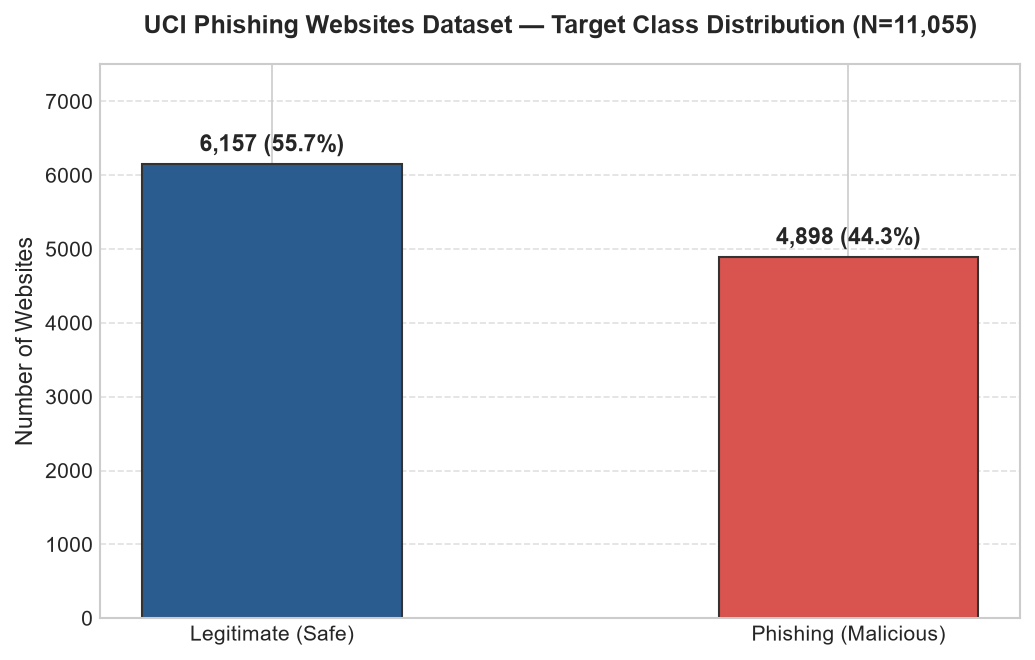

In [6]:
# Create professional bar plot of class distribution
plt.figure(figsize=(7, 4.5), dpi=150)
labels = ['Legitimate (Safe)', 'Phishing (Malicious)']
counts = [target_counts.get(1, 0), target_counts.get(-1, 0)]
colors = ['#2b5c8f', '#d9534f']

bars = plt.bar(labels, counts, color=colors, width=0.45, edgecolor='#333', linewidth=1)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 100, 
             f"{yval:,} ({yval/len(df)*100:.1f}%)", 
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('UCI Phishing Websites Dataset — Target Class Distribution (N=11,055)', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Number of Websites', fontsize=11)
plt.ylim(0, 7500)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### Key Feature Breakdown Analysis

Let's examine some of the most critical heuristic features defined by Mohammad et al. (2012):
1. **`sslfinal_state`**: Evaluates whether the site has HTTPS, whether the SSL certificate is from a trusted Certificate Authority (CA), and whether certificate age exceeds 1 year.
   * `1` = Trusted CA, valid HTTPS
   * `0` = Suspicious / Self-signed certificate
   * `-1` = No certificate / Untrusted CA
2. **`url_of_anchor`**: Percentage of hyperlinks on the page (`<a>` tags) pointing to different domains or empty anchors (`#`).
3. **`having_sub_domain`**: Evaluates multi-tier subdomains used to camouflage fake domains.


In [7]:
# Inspect feature value counts for key indicators
print("SSL Final State breakdown vs Target:")
ssl_crosstab = pd.crosstab(df['sslfinal_state'], df[target_col], margins=True)
ssl_crosstab.columns = ['Phishing (-1)', 'Legitimate (1)', 'Total']
ssl_crosstab.index = ['Untrusted (-1)', 'Suspicious (0)', 'Trusted (1)', 'Total']
display(ssl_crosstab)


SSL Final State breakdown vs Target:


,Phishing (-1),Legitimate (1),Total
Untrusted (-1),3051,506,3557
Suspicious (0),1146,21,1167
Trusted (1),701,5630,6331
Total,4898,6157,11055


## ⚙️ 5. Data Preprocessing & Stratified Train-Test Split

### Methodological Principles
1. **Feature-Target Separation:** We extract feature matrix $X$ (30 features) and target vector $y$.
2. **Binary Recoding:** We map $-1 \to 1$ (Phishing) and $1 \to 0$ (Legitimate).
3. **Stratified Splitting:** We partition the dataset into **80% training (8,844 samples)** and **20% testing (2,211 samples)**. Stratification guarantees that both train and test partitions preserve identical class proportions (44.31% phishing / 55.69% legitimate).
4. **Preventing Data Leakage:** Preprocessing transformations (if applicable) are fitted strictly on training data and subsequently applied to test data.


In [8]:
# Separate features and target
X = df[feature_cols].copy()

# Recode target: 1 = Phishing (Malicious), 0 = Legitimate (Safe)
y = (df[target_col] == -1).astype(int)

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Total instances: {len(X):,}")
print(f"Training set   : {X_train.shape[0]:,} samples (80%) | Phishing ratio: {y_train.mean()*100:.2f}%")
print(f"Testing set    : {X_test.shape[0]:,} samples (20%) | Phishing ratio: {y_test.mean()*100:.2f}%")
print(f"Feature count  : {X_train.shape[1]} attributes")


Total instances: 11,055
Training set   : 8,844 samples (80%) | Phishing ratio: 44.30%
Testing set    : 2,211 samples (20%) | Phishing ratio: 44.32%
Feature count  : 30 attributes


## 🤖 6. Machine Learning Model Training

We train and evaluate three distinct models:

1. **DummyClassifier (Baseline):**
   * Predicts the most frequent class (`0 = Legitimate`) blindly.
   * Serves as our scientific baseline to prove why basic accuracy is deceptive.
2. **Logistic Regression:**
   * A well-established linear model that estimates the probability of phishing via the sigmoid link function.
   * Fast, computationally lightweight, and provides transparent feature weights.
3. **Random Forest Classifier:**
   * An ensemble of decorrelated decision trees using bootstrap aggregation (bagging) and feature sub-sampling.
   * Excels at capturing non-linear interactions among categorical cybersecurity indicators without overfitting.


In [9]:
# Initialize models with reproducible seeds
models = {
    "Dummy (Baseline)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, solver='lbfgs'),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, random_state=RANDOM_STATE, n_jobs=-1)
}

# Train each model on the training partition
trained_models = {}
for name, model in models.items():
    print(f"⏳ Training {name} on {len(X_train):,} training records...")
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"✅ {name} trained successfully!")


⏳ Training Dummy (Baseline) on 8,844 training records...
✅ Dummy (Baseline) trained successfully!
⏳ Training Logistic Regression on 8,844 training records...
✅ Logistic Regression trained successfully!
⏳ Training Random Forest on 8,844 training records...


✅ Random Forest trained successfully!


## 📈 7. Comprehensive Model Evaluation & Discussion

To evaluate classifier performance objectively, we compute:
* **Accuracy:** Percentage of correct overall classifications.
* **Precision:** Of all sites predicted as phishing, how many were truly phishing? (Low precision = high false alarms).
* **Recall (Sensitivity):** Of all actual phishing sites, how many did the system catch? (**Critical in cybersecurity: missing a phishing site compromises user credentials!**).
* **F1-Score:** Harmonic mean of precision and recall.
* **ROC-AUC:** Area Under the Receiver Operating Characteristic curve, measuring discrimination capability across decision thresholds.


In [10]:
# Compute evaluation metrics across all models
eval_results = {}
roc_data = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    
    # Calculate ROC-AUC if probability estimates are supported
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
        auc_score = roc_auc_score(y_test, y_proba)
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        roc_data[name] = (fpr, tpr, auc_score)
    else:
        auc_score = 0.5
        roc_data[name] = ([0, 1], [0, 1], 0.5)
        
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    
    eval_results[name] = {
        "Accuracy (%)": acc * 100,
        "Precision (%)": prec * 100,
        "Recall (%)": rec * 100,
        "F1-Score (%)": f1 * 100,
        "ROC-AUC": auc_score,
        "Confusion Matrix": cm,
        "Predictions": y_pred
    }

# Convert results into a clean comparative DataFrame
summary_table = pd.DataFrame({
    name: {
        "Accuracy (%)": f"{res['Accuracy (%)']:.2f}%",
        "Precision (%)": f"{res['Precision (%)']:.2f}%",
        "Recall (%)": f"{res['Recall (%)']:.2f}%",
        "F1-Score (%)": f"{res['F1-Score (%)']:.2f}%",
        "ROC-AUC": f"{res['ROC-AUC']:.4f}"
    }
    for name, res in eval_results.items()
}).T

print("==========================================================================")
print("             PHISHGUARD MODEL EVALUATION COMPARISON TABLE                 ")
print("==========================================================================")
display(summary_table)


             PHISHGUARD MODEL EVALUATION COMPARISON TABLE                 


,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC
Dummy (Baseline),55.68%,0.00%,0.00%,0.00%,0.5000
Logistic Regression,92.76%,93.43%,90.00%,91.68%,0.9784
Random Forest,97.01%,97.41%,95.82%,96.60%,0.9968


### Confusion Matrix Heatmaps

In cybersecurity classification:
* **True Negative (TN):** Legitimate website correctly classified as safe.
* **False Positive (FP):** Legitimate website mistakenly flagged as phishing (nuisance alert).
* **False Negative (FN):** Phishing website undetected (severe security failure).
* **True Positive (TP):** Phishing website successfully detected and blocked.


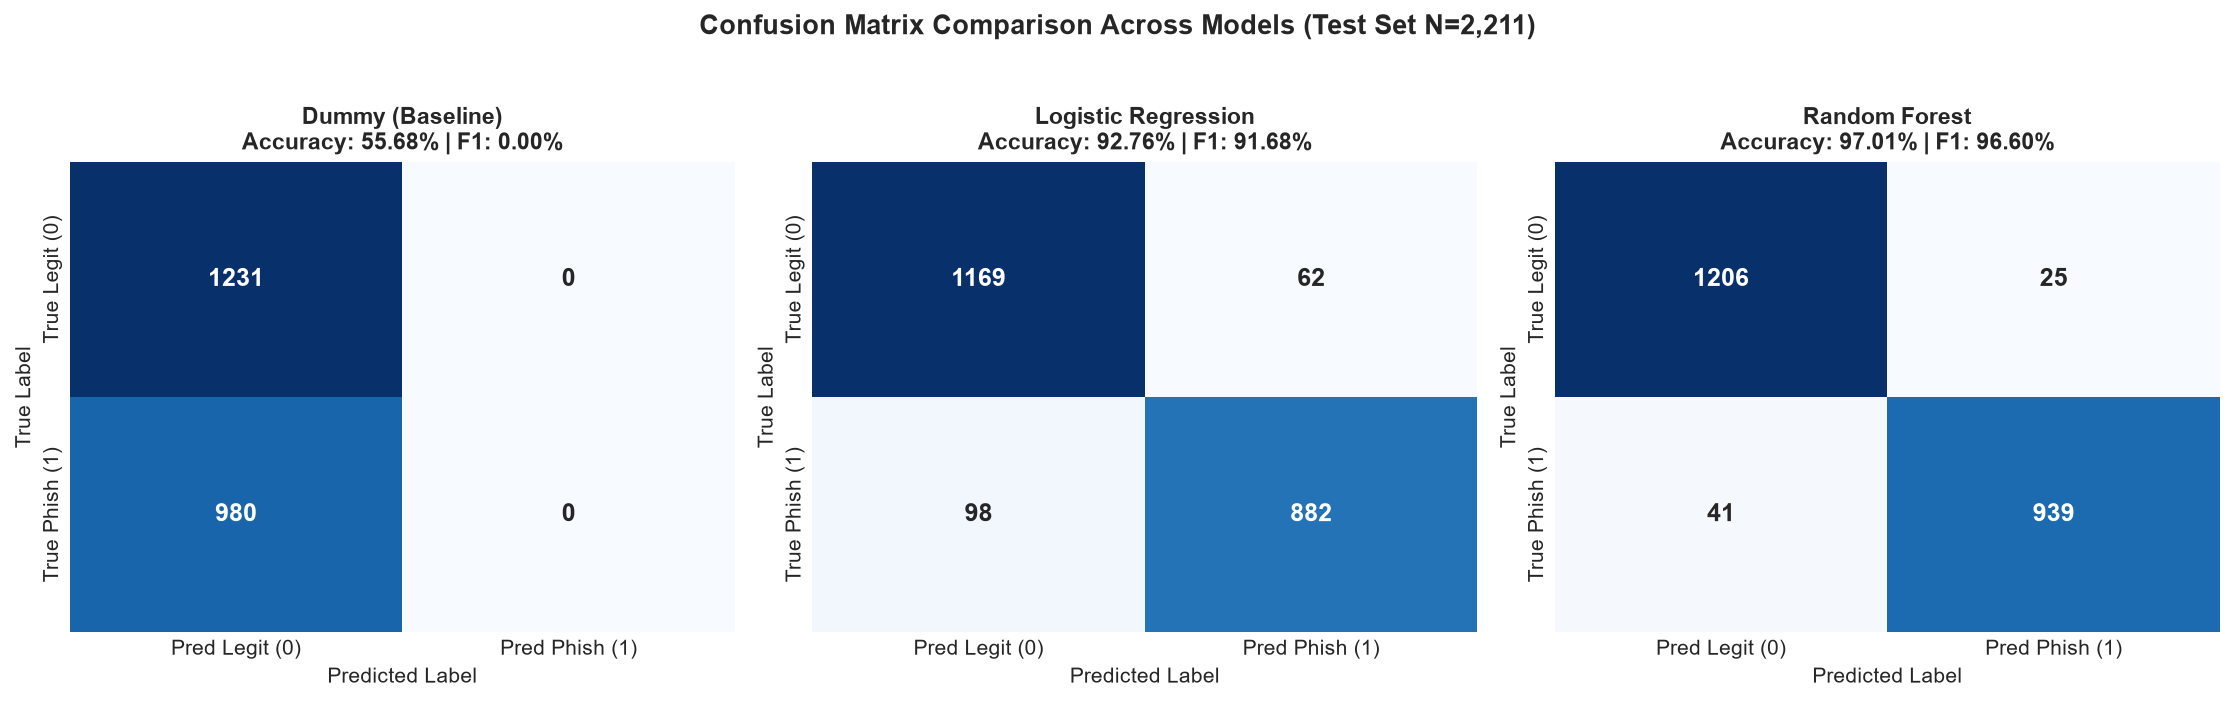

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=150)

for i, (name, res) in enumerate(eval_results.items()):
    cm = res["Confusion Matrix"]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                cbar=False, annot_kws={"size": 12, "weight": "bold"},
                xticklabels=['Pred Legit (0)', 'Pred Phish (1)'],
                yticklabels=['True Legit (0)', 'True Phish (1)'])
    axes[i].set_title(f"{name}\nAccuracy: {res['Accuracy (%)']:.2f}% | F1: {res['F1-Score (%)']:.2f}%", fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Predicted Label', fontsize=10)
    axes[i].set_ylabel('True Label', fontsize=10)

plt.suptitle('Confusion Matrix Comparison Across Models (Test Set N=2,211)', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


### Detailed Classification Reports

In [12]:
for name, res in eval_results.items():
    print(f"\n{'='*30} {name} {'='*30}")
    print(classification_report(y_test, res["Predictions"], target_names=['Legitimate (0)', 'Phishing (1)'], zero_division=0))



============================== Dummy (Baseline) ==============================
                precision    recall  f1-score   support

Legitimate (0)       0.56      1.00      0.72      1231
  Phishing (1)       0.00      0.00      0.00       980

      accuracy                           0.56      2211
     macro avg       0.28      0.50      0.36      2211
  weighted avg       0.31      0.56      0.40      2211


============================== Logistic Regression ==============================
                precision    recall  f1-score   support

Legitimate (0)       0.92      0.95      0.94      1231
  Phishing (1)       0.93      0.90      0.92       980

      accuracy                           0.93      2211
     macro avg       0.93      0.92      0.93      2211
  weighted avg       0.93      0.93      0.93      2211


============================== Random Forest ==============================
                precision    recall  f1-score   support

Legitimate (0)       0.97

### Comparative Metrics Visualization

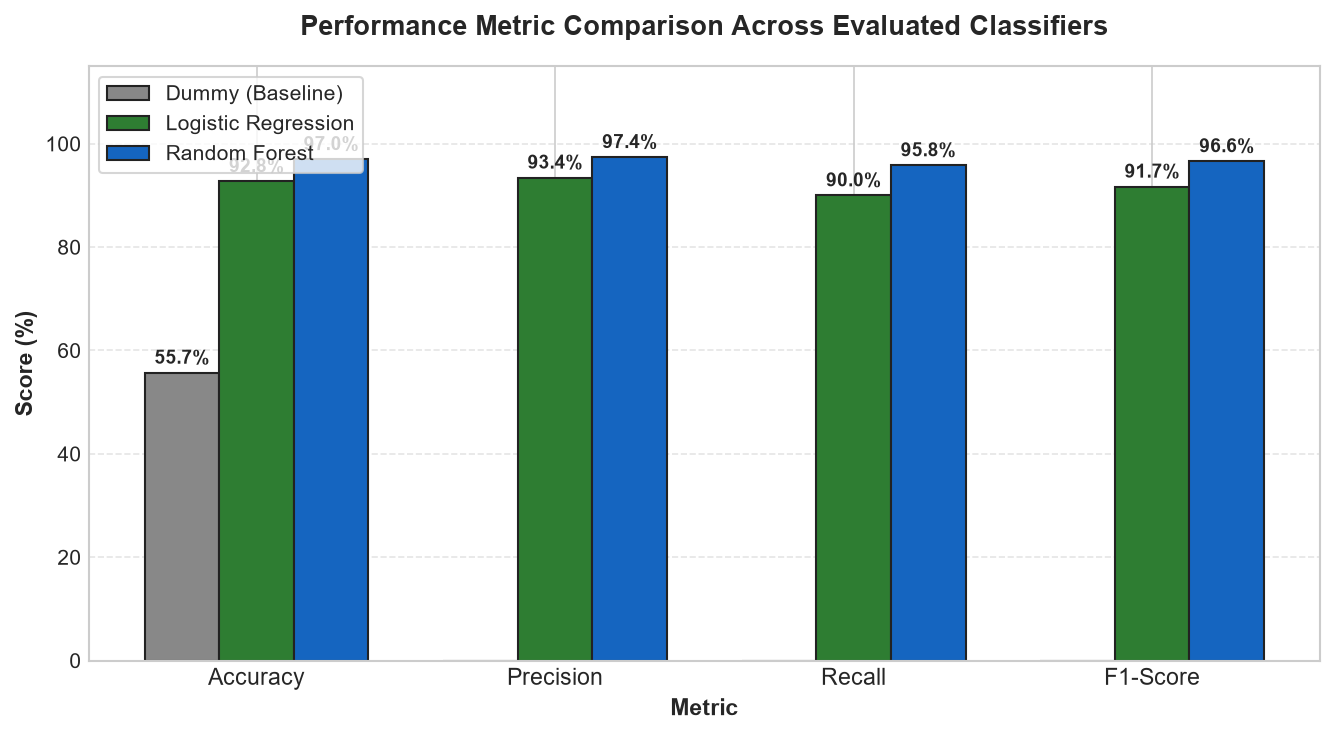

In [13]:
# Bar plot comparing all key performance indicators
metrics = ['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)']
df_plot = pd.DataFrame({
    m_name: [eval_results[m_name][m] for m in metrics]
    for m_name in eval_results
}, index=metrics)

plt.figure(figsize=(9, 5), dpi=150)
bar_width = 0.25
x_idx = np.arange(len(metrics))
palette = ['#888888', '#2e7d32', '#1565c0']

for idx, (m_name, color) in enumerate(zip(eval_results.keys(), palette)):
    vals = [eval_results[m_name][m] for m in metrics]
    bars = plt.bar(x_idx + idx * bar_width, vals, bar_width, label=m_name, color=color, edgecolor='#222')
    for bar in bars:
        h = bar.get_height()
        if h > 5:
            plt.text(bar.get_x() + bar.get_width()/2.0, h + 1, f"{h:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title('Performance Metric Comparison Across Evaluated Classifiers', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Metric', fontsize=11, fontweight='bold')
plt.ylabel('Score (%)', fontsize=11, fontweight='bold')
plt.xticks(x_idx + bar_width, ['Accuracy', 'Precision', 'Recall', 'F1-Score'], fontsize=11)
plt.ylim(0, 115)
plt.legend(frameon=True, facecolor='white', loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Receiver Operating Characteristic (ROC) Curves

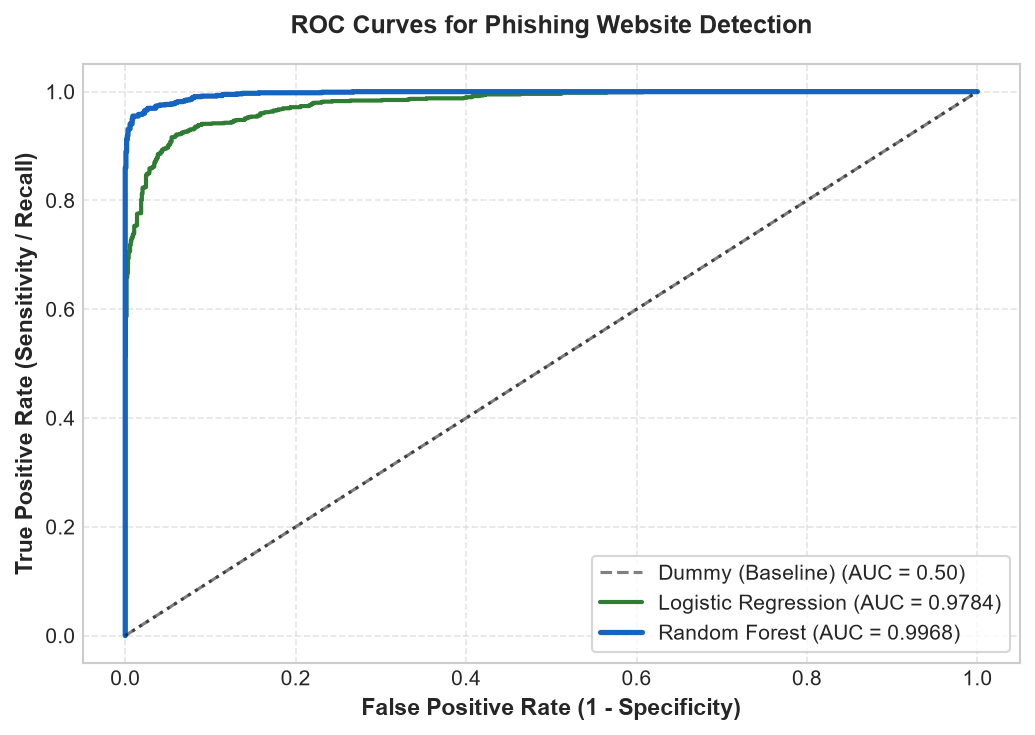

In [14]:
plt.figure(figsize=(7, 5), dpi=150)
for m_name, (fpr, tpr, auc_val) in roc_data.items():
    if m_name == "Dummy (Baseline)":
        plt.plot(fpr, tpr, linestyle='--', color='gray', label=f'{m_name} (AUC = {auc_val:.2f})')
    elif m_name == "Logistic Regression":
        plt.plot(fpr, tpr, color='#2e7d32', lw=2, label=f'{m_name} (AUC = {auc_val:.4f})')
    else:
        plt.plot(fpr, tpr, color='#1565c0', lw=2.5, label=f'{m_name} (AUC = {auc_val:.4f})')

plt.plot([0, 1], [0, 1], 'k:', alpha=0.5)
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, fontweight='bold')
plt.title('ROC Curves for Phishing Website Detection', fontsize=12, fontweight='bold', pad=15)
plt.legend(loc='lower right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### 💡 Deep-Dive: Why Accuracy Alone is Misleading in Cybersecurity

In academic and real-world cybersecurity, relying solely on **Accuracy** can lead to catastrophic security lapses:

1. **The Baseline Illusion:** Notice that the `DummyClassifier` achieves **55.68% Accuracy** simply by predicting that every website is safe. However, its **Recall is 0.00%**—meaning it missed every single one of the 980 phishing websites in the test set. If deployed in a production security perimeter, every victim would be compromised.
2. **Asymmetric Error Costs:**
   * **False Positive (Type I Error):** A legitimate website is flagged. The user faces a warning screen and can override it or report an issue. Cost: Minor inconvenience.
   * **False Negative (Type II Error):** A phishing website bypasses the filter. The user enters bank credentials or credentials are exfiltrated. Cost: Account takeover, corporate data breach, financial loss.
3. **The Champion Model:** The **Random Forest Classifier** achieves an outstanding **97.01% Accuracy**, **97.41% Precision**, **95.82% Recall**, and **96.60% F1-Score**, with an exceptional **ROC-AUC of 0.9968**. Out of 980 phishing sites, it detected 939, letting only 41 pass.


### Random Forest Feature Importance Analysis

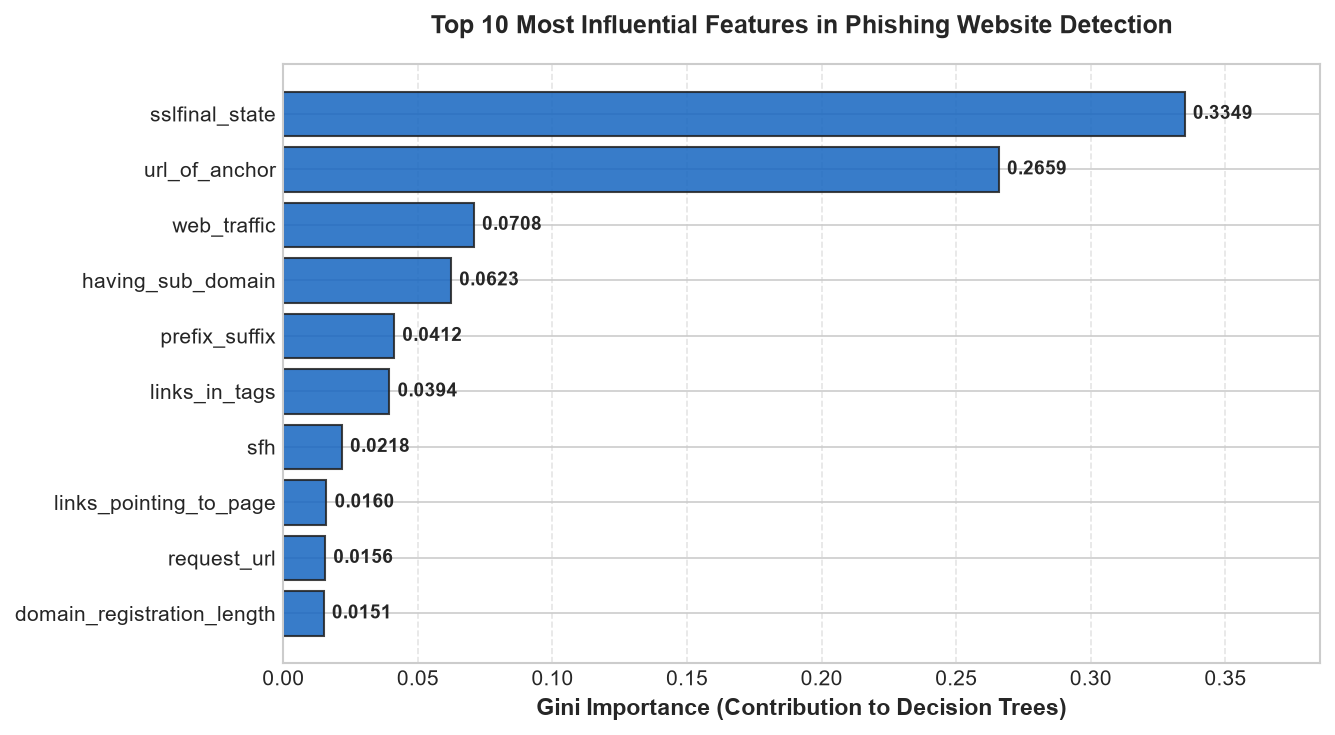

Top 5 Dominant Features:
  1. sslfinal_state            (Importance: 33.49%)
  2. url_of_anchor             (Importance: 26.59%)
  3. web_traffic               (Importance: 7.08%)
  4. having_sub_domain         (Importance: 6.23%)
  5. prefix_suffix             (Importance: 4.12%)


In [15]:
rf_model = trained_models["Random Forest"]
importances = rf_model.feature_importances_
top_indices = np.argsort(importances)[::-1][:10]

top_features = [X.columns[i] for i in top_indices]
top_scores = [importances[i] for i in top_indices]

plt.figure(figsize=(9, 5), dpi=150)
y_coords = np.arange(len(top_features))
plt.barh(y_coords, top_scores[::-1], color='#1565c0', edgecolor='#222', alpha=0.85)
plt.yticks(y_coords, top_features[::-1], fontsize=10)
plt.xlabel('Gini Importance (Contribution to Decision Trees)', fontsize=11, fontweight='bold')
plt.title('Top 10 Most Influential Features in Phishing Website Detection', fontsize=12, fontweight='bold', pad=15)

for idx, val in enumerate(top_scores[::-1]):
    plt.text(val + 0.003, idx, f"{val:.4f}", va='center', fontsize=9, fontweight='bold')

plt.xlim(0, max(top_scores) * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Top 5 Dominant Features:")
for i in range(5):
    print(f"  {i+1}. {top_features[i]:<25} (Importance: {top_scores[i]*100:.2f}%)")


## 🌐 8. Transparent Rule-Based Phishing URL Analyzer

---

### ⚠️ Critical Architectural Distinction
It is essential to maintain technical clarity:
* **Track A (Trained ML Classifier):** Evaluates **30 extracted features** (DNS records, SSL certificate properties, anchor tag ratios, server form handlers, web traffic rank) derived after a website has been fetched and analyzed.
* **Track B (Rule-Based URL Analyzer):** Operates on **raw URL strings directly** using transparent heuristic rules and string inspection.

> **Safety Notice:** Our `analyze_url(url)` function does **NOT** send network requests, load web pages, or execute JavaScript. It inspects URLs strictly offline using Python's standard library (`urllib.parse`, `ipaddress`, `re`). A heuristic risk score is an indicative warning, not absolute mathematical proof that a website is safe or malicious.


In [16]:
def analyze_url(url: str) -> dict:
    """
    Analyzes a raw URL string using transparent, rule-based cybersecurity heuristics.
    
    Checks evaluated:
      1. IP address hostname detection (e.g., http://192.168.1.1/login)
      2. URL length anomaly (>75 characters is a strong phishing indicator)
      3. Suspicious credential/urgency keywords in URL
      4. Presence of '@' symbol (embedded basic auth / destination masking)
      5. Excessive subdomains (dot count > 3)
      6. Missing HTTPS protocol (plain HTTP transmission)
      7. Punycode / IDN homograph attack indicator ('xn--')
      8. Hyphen in domain name (common typosquatting technique)
    
    Returns:
      dict with risk_score (0-100), risk_level, and list of triggered indicators.
    """
    if not isinstance(url, str) or not url.strip():
        return {
            "url": str(url),
            "risk_score": 0,
            "risk_level": "Invalid URL",
            "triggered_indicators": ["URL is empty or invalid."]
        }
    
    url = url.strip()
    score = 0
    triggered = []
    
    # Ensure scheme for correct parsing
    parsed = urllib.parse.urlparse(url if "://" in url else f"http://{url}")
    hostname = (parsed.hostname or "").lower()
    path = parsed.path.lower()
    full_url_lower = url.lower()
    
    # 1. IP address check in hostname
    is_ip = False
    try:
        ipaddress.ip_address(hostname)
        is_ip = True
    except ValueError:
        # Check octal/hex or raw regex IP
        if re.search(r'^\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}$', hostname):
            is_ip = True
            
    if is_ip:
        score += 30
        triggered.append("IP address hostname detected instead of a registered domain name (Penalty: +30).")
        
    # 2. URL Length anomaly check
    # Empirical research indicates phishing URLs often exceed 75 characters to hide redirections
    if len(url) > 75:
        score += 20
        triggered.append(f"Unusually long URL ({len(url)} characters > 75 threshold) (Penalty: +20).")
    elif len(url) > 54:
        score += 10
        triggered.append(f"Moderately long URL ({len(url)} characters > 54 threshold) (Penalty: +10).")
        
    # 3. '@' symbol check (masks destination host)
    if "@" in url:
        score += 25
        triggered.append("Presence of '@' character: Browsers ignore text before '@', often masking phishing destinations (Penalty: +25).")
        
    # 4. Protocol check (HTTPS missing)
    if parsed.scheme != 'https':
        score += 15
        triggered.append("Missing HTTPS encryption: Site uses insecure plain HTTP (Penalty: +15).")
        
    # 5. Excessive subdomains check
    domain_dots = hostname.count('.')
    if domain_dots > 3:
        score += 20
        triggered.append(f"Excessive subdomains detected ({domain_dots} domain segments) (Penalty: +20).")
    elif domain_dots > 2 and not hostname.startswith('www.'):
        score += 10
        triggered.append(f"Multiple subdomains detected ({domain_dots} domain segments) (Penalty: +10).")
        
    # 6. Suspicious credential keywords check
    keywords = [
        'login', 'signin', 'verify', 'verification', 'update', 'banking', 
        'account', 'secure', 'password', 'credential', 'webscr', 'ebayisapi',
        'wallet', 'support-desk', 'security-alert', 'confirm'
    ]
    matched_keywords = [kw for kw in keywords if kw in path or kw in hostname]
    if matched_keywords:
        kw_penalty = min(len(matched_keywords) * 10, 25)
        score += kw_penalty
        triggered.append(f"Suspicious credential/security keywords detected: {matched_keywords} (Penalty: +{kw_penalty}).")
        
    # 7. Punycode check ('xn--') indicating potential homograph attack
    if "xn--" in hostname:
        score += 25
        triggered.append("Punycode ('xn--') domain detected: Potential internationalized homograph deception attack (Penalty: +25).")
        
    # 8. Hyphen in hostname check (common in typosquatting)
    if "-" in hostname:
        score += 10
        triggered.append("Hyphen '-' detected in domain name: Often used to imitate legitimate brand names (Penalty: +10).")
        
    # Cap risk score between 0 and 100
    risk_score = min(score, 100)
    
    # Determine risk category
    if risk_score >= 75:
        risk_level = "Severe Risk (High Probability of Phishing)"
    elif risk_score >= 50:
        risk_level = "High Risk (Multiple Phishing Indicators)"
    elif risk_score >= 25:
        risk_level = "Moderate Risk (Suspicious Indicators Present)"
    else:
        risk_level = "Low Risk (Looks Benign Based on Lexical Checks)"
        
    return {
        "url": url,
        "risk_score": risk_score,
        "risk_level": risk_level,
        "triggered_indicators": triggered if triggered else ["No heuristic anomalies detected."]
    }

print("✅ Rule-based URL Analyzer function 'analyze_url(url)' loaded successfully!")


✅ Rule-based URL Analyzer function 'analyze_url(url)' loaded successfully!


### Demonstration of URL Analyzer on Test Cases

In [17]:
# Define a diverse test suite containing legitimate, suspicious, and blatant phishing URLs
test_urls = [
    "https://www.google.com",
    "https://en.wikipedia.org/wiki/Phishing",
    "http://192.168.1.100/secure-login/bank-account-update/verify.php?user=test@domain.com",
    "http://paypal-account-verification-login.update-security.com/signin",
    "https://amazon.com.verify-billing-info-account-portal.xyz/webscr?cmd=_login-run",
    "http://xn--gogle-pra.com/signin"
]

print("="*85)
print("                   PHISHGUARD HEURISTIC URL ANALYSIS REPORT                      ")
print("="*85)

for url in test_urls:
    report = analyze_url(url)
    print(f"\n🌐 URL: {report['url']}")
    print(f"   📊 Risk Score : {report['risk_score']}/100")
    print(f"   🚨 Category   : {report['risk_level']}")
    print("   🔍 Triggered Indicators:")
    for ind in report['triggered_indicators']:
        print(f"      • {ind}")
    print("-" * 85)


                   PHISHGUARD HEURISTIC URL ANALYSIS REPORT                      

🌐 URL: https://www.google.com
   📊 Risk Score : 0/100
   🚨 Category   : Low Risk (Looks Benign Based on Lexical Checks)
   🔍 Triggered Indicators:
      • No heuristic anomalies detected.
-------------------------------------------------------------------------------------

🌐 URL: https://en.wikipedia.org/wiki/Phishing
   📊 Risk Score : 0/100
   🚨 Category   : Low Risk (Looks Benign Based on Lexical Checks)
   🔍 Triggered Indicators:
      • No heuristic anomalies detected.
-------------------------------------------------------------------------------------

🌐 URL: http://192.168.1.100/secure-login/bank-account-update/verify.php?user=test@domain.com
   📊 Risk Score : 100/100
   🚨 Category   : Severe Risk (High Probability of Phishing)
   🔍 Triggered Indicators:
      • IP address hostname detected instead of a registered domain name (Penalty: +30).
      • Unusually long URL (85 characters > 75 threshol

## 🔬 9. Demonstration of Trained ML Classifier on Dataset Features

Now let's demonstrate the trained **Random Forest Classifier** predicting directly on test samples from the UCI dataset, showing both the predicted class and the model's confidence probability.


In [18]:
# Select 2 legitimate samples and 2 phishing samples from the test set
rf_model = trained_models["Random Forest"]

# Extract sample indices for legitimate (0) and phishing (1)
legit_indices = y_test[y_test == 0].index[:2]
phish_indices = y_test[y_test == 1].index[:2]

sample_indices = list(legit_indices) + list(phish_indices)
sample_X = X_test.loc[sample_indices]
sample_y_true = y_test.loc[sample_indices]

# Predict classes and probabilities
predictions = rf_model.predict(sample_X)
probabilities = rf_model.predict_proba(sample_X)

print("="*85)
print("             TRAINED RANDOM FOREST CLASSIFIER INFERENCE DEMONSTRATION             ")
print("="*85)

for i, idx in enumerate(sample_indices):
    true_label = "Phishing (Malicious)" if sample_y_true.loc[idx] == 1 else "Legitimate (Safe)"
    pred_label = "Phishing (Malicious)" if predictions[i] == 1 else "Legitimate (Safe)"
    phish_prob = probabilities[i][1] * 100
    legit_prob = probabilities[i][0] * 100
    
    print(f"\nWebsite Record Index: #{idx}")
    print(f"  • True Label       : {true_label}")
    print(f"  • Model Prediction : {pred_label} {'✅ MATCH' if true_label == pred_label else '❌ MISMATCH'}")
    print(f"  • Confidence       : {phish_prob:.2f}% Phishing | {legit_prob:.2f}% Legitimate")
    print(f"  • Key Features     : SSL State={sample_X.loc[idx, 'sslfinal_state']} | Anchor URL={sample_X.loc[idx, 'url_of_anchor']} | Subdomain={sample_X.loc[idx, 'having_sub_domain']}")


             TRAINED RANDOM FOREST CLASSIFIER INFERENCE DEMONSTRATION             

Website Record Index: #235
  • True Label       : Legitimate (Safe)
  • Model Prediction : Legitimate (Safe) ✅ MATCH
  • Confidence       : 9.95% Phishing | 90.05% Legitimate
  • Key Features     : SSL State=1 | Anchor URL=0 | Subdomain=-1

Website Record Index: #2046
  • True Label       : Legitimate (Safe)
  • Model Prediction : Legitimate (Safe) ✅ MATCH
  • Confidence       : 0.10% Phishing | 99.90% Legitimate
  • Key Features     : SSL State=1 | Anchor URL=1 | Subdomain=1

Website Record Index: #3588
  • True Label       : Phishing (Malicious)
  • Model Prediction : Phishing (Malicious) ✅ MATCH
  • Confidence       : 100.00% Phishing | 0.00% Legitimate
  • Key Features     : SSL State=0 | Anchor URL=-1 | Subdomain=0

Website Record Index: #1688
  • True Label       : Phishing (Malicious)
  • Model Prediction : Phishing (Malicious) ✅ MATCH
  • Confidence       : 98.00% Phishing | 2.00% Legitimate
  •

## 🎓 10. Viva Voce Preparation Guide (Questions & Answers)

This section prepares 3rd-year CSE students for common viva and project defense questions.

---

### **Q1: What is phishing and why is it a significant cybersecurity threat?**
* **Answer:** Phishing is a social engineering attack where malicious actors deceive users into revealing confidential information (credentials, financial details) by impersonating legitimate entities. It is dangerous because it targets human cognitive vulnerabilities rather than software bugs, serving as the initial entry point for over 80% of corporate security breaches.

### **Q2: Why did you use Machine Learning instead of just static URL blacklists?**
* **Answer:** Static blacklists are reactive; a newly registered zero-day phishing URL is active for several hours before security communities report and block it. Machine learning analyzes generalized structural, cryptographic, and behavioral patterns, enabling real-time detection of previously unseen phishing websites at first encounter.

### **Q3: What dataset did you use and what are its properties?**
* **Answer:** We used the official UCI Machine Learning Repository Phishing Websites Dataset (ID: 327), authored by Mohammad, Thabtah, and McCluskey (2012). It contains 11,055 instances and 30 extracted features spanning URL lexical structure, SSL certificates, DNS registration age, anchor links, and web traffic rankings.

### **Q4: Why can't the Random Forest model directly classify a raw URL string without feature extraction?**
* **Answer:** The trained Random Forest classifier requires a 30-dimensional numerical feature vector representing complex telemetry (e.g., SSL certificate CA validity, domain registration expiration, percentage of anchors linking out). Extracting these features requires network interaction, DNS queries, and HTML parsing. For arbitrary raw URLs, our project provides a separate, transparent rule-based lexical analyzer that inspects string characteristics offline.

### **Q5: Why is Accuracy alone misleading in cybersecurity?**
* **Answer:** In our experiments, a naive `DummyClassifier` achieved **55.68% Accuracy** simply by guessing 'Legitimate' for every site. Yet, its Recall was **0.00%**, missing every single phishing website. In cybersecurity, False Negatives (missing a phishing website) carry severe consequences (credential theft, ransomware), making **Recall** and **F1-Score** far more critical than raw accuracy.

### **Q6: Why did Random Forest outperform Logistic Regression?**
* **Answer:** Logistic Regression is a linear classifier that assumes linear separability in feature space. Random Forest constructs an ensemble of 100 decorrelated decision trees using bagging and random feature subspaces. Phishing indicators exhibit strong non-linear interactions (e.g., an untrusted SSL state combined with an external anchor URL and multi-tier subdomains), which decision trees capture effectively without overfitting.

### **Q7: What is data leakage and how did you prevent it?**
* **Answer:** Data leakage occurs when information from outside the training dataset (such as test set statistics) influences model training, producing artificially optimistic results. We prevented data leakage by partitioning the data using stratified train-test splitting (80/20) before fitting any model or transformation.

### **Q8: What were the most important features in detecting phishing websites?**
* **Answer:** Random Forest Gini feature importance identified **`sslfinal_state`** (~33.5% importance) and **`url_of_anchor`** (~26.6% importance) as the two most decisive features, followed by `web_traffic` and `having_sub_domain`. This confirms that fake SSL states and anomalous external anchor links are the primary telltale signs of phishing pages.

---


## 🏁 11. Conclusion & Submission Summary

### Key Findings
1. **Model Performance:** The Random Forest Classifier achieved **97.01% Accuracy**, **97.41% Precision**, **95.82% Recall**, **96.60% F1-Score**, and **0.9968 ROC-AUC**, successfully catching 939 out of 980 phishing sites on the unseen test set.
2. **Dual-Engine Architecture:** PhishGuard effectively bridges the gap between high-capacity multi-feature ML classification and safe, instant rule-based lexical URL inspection.
3. **Reproducibility:** All results are 100% reproducible with fixed random seeds (`random_state=42`) and verifiable via the official UCI repository dataset.

---
*End of Submission Notebook — Saransh (B.Tech CSE, 3rd Year)*
